# 01 — Data preparation and exploration

Builds `data/processed/bitcoin_daily.csv`: one row per `target_date`, the observed fee `actual_fee_sat` and 14 inputs from the 7 previous calendar days. Run from the `notebooks/` folder.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..')
RAW = ROOT / 'data/raw/coinmetrics_btc_daily.csv'
URL = ('https://community-api.coinmetrics.io/v4/timeseries/asset-metrics'
       '?assets=btc&metrics=FeeTotNtv,TxCnt&start_time=2020-01-01&end_time=2024-12-31'
       '&frequency=1d&page_size=2000&format=csv')
if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(URL).to_csv(RAW, index=False)

## 1. Load, sort and check

In [2]:
raw = pd.read_csv(RAW)
raw['date'] = pd.to_datetime(raw['time']).dt.tz_localize(None).dt.normalize()
raw = raw.sort_values('date').reset_index(drop=True)

full_range = pd.date_range('2020-01-01', '2024-12-31', freq='D')
checks = {
    'rows': len(raw),
    'duplicate_dates': int(raw['date'].duplicated().sum()),
    'missing_dates': len(full_range.difference(raw['date'])),
    'missing_FeeTotNtv': int(raw['FeeTotNtv'].isna().sum()),
    'missing_TxCnt': int(raw['TxCnt'].isna().sum()),
    'zero_TxCnt_days': int((raw['TxCnt'] == 0).sum()),
}
checks

{'rows': 1827,
 'duplicate_dates': 0,
 'missing_dates': 0,
 'missing_FeeTotNtv': 0,
 'missing_TxCnt': 0,
 'zero_TxCnt_days': 0}

In [3]:
assert checks['rows'] == 1827
assert checks['duplicate_dates'] == 0 and checks['missing_dates'] == 0

## 2. Average fee per transaction (satoshis)

`fee_sat = 100_000_000 * FeeTotNtv / TxCnt`. A day is flagged when the ratio is impossible (missing value or `TxCnt <= 0`).

In [4]:
daily = raw.set_index('date')[['FeeTotNtv', 'TxCnt']].reindex(full_range)
daily.index.name = 'date'
daily['fee_invalid'] = daily['FeeTotNtv'].isna() | daily['TxCnt'].isna() | (daily['TxCnt'] <= 0)
daily['fee_sat'] = (100_000_000 * daily['FeeTotNtv'] / daily['TxCnt']).where(~daily['fee_invalid'])
print('Flagged days:', int(daily['fee_invalid'].sum()))
daily.head()

Flagged days: 0


,FeeTotNtv,TxCnt,fee_invalid,fee_sat
date,,,,
2020-01-01,9.886246,251867,False,3925.185054
2020-01-02,13.720930,291935,False,4699.994821
2020-01-03,16.610931,323153,False,5140.268210
2020-01-04,12.148490,282301,False,4303.381695
2020-01-05,11.890081,288212,False,4125.463718


## 3. One row per `target_date` with 7 days of history

`fee_lag_k_sat` / `txcnt_lag_k` = value k calendar days before the target date (k = 1..7). Shifts are done on a complete calendar index, so a lag is always exactly k days back.

In [5]:
ds = pd.DataFrame(index=daily.index.copy())
ds['actual_fee_sat'] = daily['fee_sat']
for k in range(1, 8):
    ds[f'fee_lag_{k}_sat'] = daily['fee_sat'].shift(k)
for k in range(1, 8):
    ds[f'txcnt_lag_{k}'] = daily['TxCnt'].shift(k)
ds.index.name = 'target_date'
ds = ds.reset_index()

year = ds['target_date'].dt.year
ds['split'] = pd.cut(year, bins=[2019, 2022, 2023, 2024], labels=['train', 'validation', 'test']).astype(str)

complete = ds.notna().all(axis=1)
removed = ds.loc[~complete, ['target_date', 'split']]
print('Rows removed (incomplete history or target):', len(removed))
print(removed.groupby('split').size())
ds = ds[complete].reset_index(drop=True)
ds.groupby('split').size()

Rows removed (incomplete history or target): 7
split
train    7
dtype: int64


split
test           366
train         1089
validation     365
dtype: int64

Sanity check on the example from the plan: the forecast for 1 January 2023 is in validation, and `fee_lag_1_sat` equals the observed fee on 31 December 2022.

In [6]:
row = ds.set_index('target_date').loc['2023-01-01']
assert row['split'] == 'validation'
assert row['fee_lag_1_sat'] == daily.loc['2022-12-31', 'fee_sat']
assert row['fee_lag_7_sat'] == daily.loc['2022-12-25', 'fee_sat']
row[['split', 'actual_fee_sat', 'fee_lag_1_sat', 'fee_lag_7_sat']]

split              validation
actual_fee_sat    3757.104581
fee_lag_1_sat     5013.823957
fee_lag_7_sat     6889.167504
Name: 2023-01-01 00:00:00, dtype: object

In [7]:
cols = ['target_date', 'split', 'actual_fee_sat'] + [f'fee_lag_{k}_sat' for k in range(1, 8)] + [f'txcnt_lag_{k}' for k in range(1, 8)]
ds = ds[cols]
ds[[f'txcnt_lag_{k}' for k in range(1, 8)]] = ds[[f'txcnt_lag_{k}' for k in range(1, 8)]].astype('int64')
OUT = ROOT / 'data/processed/bitcoin_daily.csv'
OUT.parent.mkdir(parents=True, exist_ok=True)
ds.to_csv(OUT, index=False, date_format='%Y-%m-%d')
print(OUT, ds.shape)

..\data\processed\bitcoin_daily.csv (1820, 17)


## 4. Exploration on the training period (2020–2022)

Median fee: 7,971 sat/tx
Max fee:    112,514 sat/tx on 2021-04-21


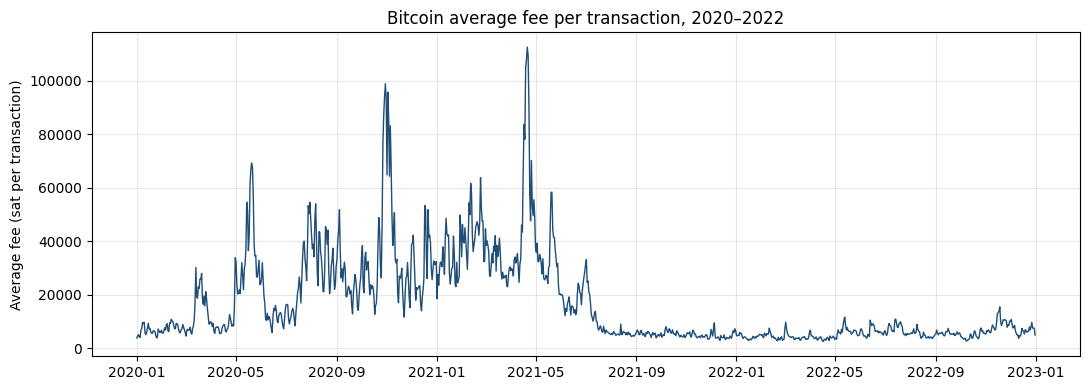

In [8]:
train = daily.loc['2020-01-01':'2022-12-31']
print(f"Median fee: {train['fee_sat'].median():,.0f} sat/tx")
print(f"Max fee:    {train['fee_sat'].max():,.0f} sat/tx on {train['fee_sat'].idxmax().date()}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.index, train['fee_sat'], lw=1, color='#1f4e79')
ax.set_ylabel('Average fee (sat per transaction)')
ax.set_title('Bitcoin average fee per transaction, 2020–2022')
ax.grid(alpha=.3)
fig.tight_layout()
(ROOT / 'reports').mkdir(exist_ok=True)
fig.savefig(ROOT / 'reports/fee_train.png', dpi=120)
plt.show()

### Transaction counts around the largest spike

In [9]:
peak = train['fee_sat'].idxmax()
window = train.loc[peak - pd.Timedelta(days=7): peak + pd.Timedelta(days=7), ['fee_sat', 'TxCnt']]
window['TxCnt_vs_train_median'] = window['TxCnt'] / train['TxCnt'].median()
print(f"Train median TxCnt: {train['TxCnt'].median():,.0f}")
window.round(2)

Train median TxCnt: 275,194


,fee_sat,TxCnt,TxCnt_vs_train_median
date,,,
2021-04-14,46035.26,295564,1.07
2021-04-15,43457.16,358905,1.30
2021-04-16,66094.59,218612,0.79
2021-04-17,83615.90,195677,0.71
2021-04-18,78134.42,276174,1.00
2021-04-19,104983.09,207290,0.75
2021-04-20,107925.17,280365,1.02
2021-04-21,112514.15,226747,0.82
2021-04-22,109316.43,269958,0.98
